# Third Phase – Experiments: Probabilistic Forecasting of Bakery and Dairy Sales
**Intelligent Systems – Universidad de Ibagué** · Stephany Trujillo, Johan Soriano, Cristian Cardona

This notebook runs every experiment described in the phase 3 report, under one protocol:

| Step | What it does |
|---|---|
| 1–3 | Loads the Kaggle *Store Sales* files and builds the 108 series (54 stores × BREAD/BAKERY, DAIRY) |
| 4 | Exploratory analysis (weekly pattern, paydays, holidays, promotions) |
| 5 | Baselines: seasonal naive and ETS |
| 6 | Quantile LightGBM (global) |
| 7 | **LSTM encoder–decoder** with embeddings and non-crossing quantile head |
| 8 | GRU variant |
| 9 | Results table (validation folds and holdout test), by family |
| 10 | Newsvendor order simulation, anomaly alerts, integrated gradients |
| 11 | *(Optional)* Temporal Fusion Transformer |

**How to run it**
1. `Runtime → Change runtime type → T4 GPU`.
2. Download the data from https://www.kaggle.com/c/store-sales-time-series-forecasting/data (you must accept the competition rules) and upload `train.csv`, `stores.csv`, `oil.csv`, `holidays_events.csv` and `transactions.csv` to `/content/data` (left panel → Files). Option B in step 1 uses the Kaggle API instead.
3. `Runtime → Run all`. Expected time on a T4: about 30–45 minutes without the TFT (the TFT adds 15–30 minutes).
4. At the end, download `results_phase3.zip` (it contains the results tables and all figures).

In [ ]:
!pip -q install lightgbm statsmodels

## 0. Configuration

In [ ]:
import os, time, math, copy, warnings
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
warnings.filterwarnings("ignore")

SEED = 42
np.random.seed(SEED)
DATA_DIR = "/content/data"
OUT_DIR = "/content/results"
os.makedirs(DATA_DIR, exist_ok=True); os.makedirs(OUT_DIR, exist_ok=True)

FAMILIES = ["BREAD/BAKERY", "DAIRY"]
ENC_LEN, H = 56, 16                       # 56 days of history, 16 days of horizon
VAL_ORIGINS = ["2017-05-28", "2017-06-13", "2017-06-29", "2017-07-15"]   # 4 validation folds
TEST_ORIGIN = "2017-07-31"                # holdout test: Jul 31 – Aug 15, 2017
QUANTILES = [0.1, 0.5, 0.9]
RUN_TFT = False                           # set True to run the optional TFT (step 11)
RESULTS = []                              # every metric row ends up here

## 1. Data

In [ ]:
# Option B: download with the Kaggle API (needs kaggle.json from your Kaggle account)
USE_KAGGLE_API = False
if USE_KAGGLE_API:
    from google.colab import files
    files.upload()   # choose kaggle.json
    !mkdir -p ~/.kaggle && mv kaggle.json ~/.kaggle/ && chmod 600 ~/.kaggle/kaggle.json
    !kaggle competitions download -c store-sales-time-series-forecasting -p /content/data
    !cd /content/data && unzip -o -q store-sales-time-series-forecasting.zip

needed = ["train.csv", "stores.csv", "oil.csv", "holidays_events.csv", "transactions.csv"]
missing = [f for f in needed if not os.path.exists(os.path.join(DATA_DIR, f))]
assert not missing, f"Upload these files to {DATA_DIR}: {missing}"
print("All files found.")

All files found.


In [ ]:
train = pd.read_csv(f"{DATA_DIR}/train.csv", parse_dates=["date"])
stores = pd.read_csv(f"{DATA_DIR}/stores.csv")
oil = pd.read_csv(f"{DATA_DIR}/oil.csv", parse_dates=["date"])
hol = pd.read_csv(f"{DATA_DIR}/holidays_events.csv", parse_dates=["date"])
trans = pd.read_csv(f"{DATA_DIR}/transactions.csv", parse_dates=["date"])

dates = pd.date_range(train.date.min(), train.date.max(), freq="D")   # complete calendar
T = len(dates)
date_idx = {d: i for i, d in enumerate(dates)}
store_ids = sorted(stores.store_nbr.unique())
series = [(f, s) for f in FAMILIES for s in store_ids]
S = len(series)
print(f"{T} days ({dates[0].date()} – {dates[-1].date()}), {S} series")

# A store is closed on a day when it sold nothing in ANY family (or the day is missing, e.g. Dec 25)
store_day = (train.groupby(["store_nbr", "date"])["sales"].sum()
             .unstack("date").reindex(index=store_ids, columns=dates).fillna(0))
CLOSED_STORE = (store_day.values == 0).astype(np.float32)

sub = train[train.family.isin(FAMILIES)]
mi = pd.MultiIndex.from_tuples(series, names=["family", "store_nbr"])
def to_matrix(col):
    return (sub.pivot_table(index=["family", "store_nbr"], columns="date", values=col, aggfunc="sum")
               .reindex(index=mi, columns=dates).fillna(0).values.astype(np.float32))
SALES = to_matrix("sales")                 # [S, T] units
PROMO_RAW = to_matrix("onpromotion")
Y = np.log1p(SALES)                        # target in log(1+x)

st_pos = np.array([store_ids.index(s) for _, s in series])
CLOSED = CLOSED_STORE[st_pos]
FIRST = np.array([np.argmax(r > 0) if (r > 0).any() else T for r in SALES])   # first day with sales
OPEN = ((np.arange(T)[None, :] >= FIRST[:, None]) & (CLOSED == 0)).astype(np.float32)
print("Series whose store opened after Feb 2013:", int((FIRST > 31).sum()))

1688 days (2013-01-01 – 2017-08-15), 108 series
Series whose store opened after Feb 2013: 16


## 2. Covariates

In [ ]:
# Transactions (past covariate only) and oil (linear interpolation of missing days)
tr_m = (trans.pivot_table(index="store_nbr", columns="date", values="transactions", aggfunc="sum")
             .reindex(index=store_ids, columns=dates).fillna(0).values)
TRANS = (np.log1p(tr_m)[st_pos] / 10).astype(np.float32)
OIL = (oil.set_index("date")["dcoilwtico"].reindex(dates)
          .interpolate(limit_direction="both").values / 100).astype(np.float32)

# Calendar
DOW = dates.dayofweek.values
DOM = dates.day.values
MONTH = dates.month.values
PAYDAY = ((DOM == 15) | dates.is_month_end).astype(np.float32)        # public-sector paydays
QUAKE = ((dates >= "2016-04-16") & (dates <= "2016-05-15")).astype(np.float32)

# Holidays: drop transferred rows (the real day appears as type 'Transfer') and 'Work Day'
h = hol[(hol.transferred.astype(str).str.lower() != "true") & (hol.type != "Work Day")]
nat_days = set(h.loc[h.locale == "National", "date"])
HOL = np.zeros((S, T, 3), np.float32)
HOL[:, :, 0] = np.array([d in nat_days for d in dates], np.float32)
sinfo = stores.set_index("store_nbr")
reg = h[h.locale == "Regional"]; loc = h[h.locale == "Local"]
for i, (_, s) in enumerate(series):
    for d in reg.loc[reg.locale_name == sinfo.loc[s, "state"], "date"]:
        if d in date_idx: HOL[i, date_idx[d], 1] = 1
    for d in loc.loc[loc.locale_name == sinfo.loc[s, "city"], "date"]:
        if d in date_idx: HOL[i, date_idx[d], 2] = 1
PROMO = (np.log1p(PROMO_RAW) / 5).astype(np.float32)

# KNOWN covariates (known in advance, used by encoder AND decoder): 18 channels
#  0-6 day of week one-hot | 7-8 day of month sin/cos | 9-10 month sin/cos | 11 payday
#  12 national holiday | 13 regional | 14 local | 15 promotion | 16 closed | 17 earthquake
cal = np.concatenate([np.eye(7)[DOW],
                      np.sin(2*np.pi*DOM/31)[:, None], np.cos(2*np.pi*DOM/31)[:, None],
                      np.sin(2*np.pi*(MONTH-1)/12)[:, None], np.cos(2*np.pi*(MONTH-1)/12)[:, None],
                      PAYDAY[:, None]], axis=1).astype(np.float32)
KNOWN = np.concatenate([np.broadcast_to(cal, (S, T, 12)), HOL, PROMO[..., None], CLOSED[..., None],
                        np.broadcast_to(QUAKE[None, :, None], (S, T, 1))], axis=-1).astype(np.float32)
PAST = np.stack([TRANS, np.broadcast_to(OIL, (S, T))], axis=-1).astype(np.float32)   # past only

# Static categorical inputs (embeddings)
FAM_IDX = np.array([FAMILIES.index(f) for f, _ in series])
STORE_IDX = st_pos
TYPE_IDX = pd.Categorical(sinfo.loc[[s for _, s in series], "type"]).codes.astype(int)
CLUSTER_IDX = pd.Categorical(sinfo.loc[[s for _, s in series], "cluster"]).codes.astype(int)
CARD = (len(store_ids), int(TYPE_IDX.max())+1, int(CLUSTER_IDX.max())+1, len(FAMILIES))
VAL_O = [date_idx[pd.Timestamp(d)] for d in VAL_ORIGINS]
TEST_O = date_idx[pd.Timestamp(TEST_ORIGIN)]
print("KNOWN", KNOWN.shape, "PAST", PAST.shape, "cardinalities", CARD)

KNOWN (108, 1688, 18) PAST (108, 1688, 2) cardinalities (54, 5, 17, 2)


## 3. Evaluation helpers (same metrics for every model)

In [ ]:
def pinball(y, q, tau):
    d = y - q
    return np.maximum(tau * d, (tau - 1) * d)

def evaluate(model_name, split, preds):
    # preds: {origin_idx: array [S, H, 3] of log(1+x) quantiles}. Only open days are scored.
    for fam in range(len(FAMILIES)):
        rows = FAM_IDX == fam
        y = np.stack([Y[rows, o:o+H] for o in preds])
        m = np.stack([OPEN[rows, o:o+H] for o in preds]) > 0
        q = np.maximum(np.sort(np.stack([preds[o][rows] for o in preds]), axis=-1), 0)
        yl, q10, q50, q90 = y[m], q[..., 0][m], q[..., 1][m], q[..., 2][m]
        yu, pu = np.expm1(yl), np.expm1(q50)
        RESULTS.append(dict(
            model=model_name, split=split, family=FAMILIES[fam],
            RMSLE=np.sqrt(np.mean((q50 - yl) ** 2)),
            WAPE_pct=100 * np.abs(yu - pu).sum() / yu.sum(),
            MAE=np.abs(yu - pu).mean(),
            Pinball_log=np.mean([pinball(yl, qq, t).mean() for qq, t in zip([q10, q50, q90], QUANTILES)]),
            Coverage_10_90_pct=100 * np.mean((yl >= q10) & (yl <= q90))))
    return pd.DataFrame([r for r in RESULTS if r["model"] == model_name and r["split"] == split])

PREDS = {}   # PREDS[model] = {origin_idx: [S,H,3]}

## 4. Exploratory analysis

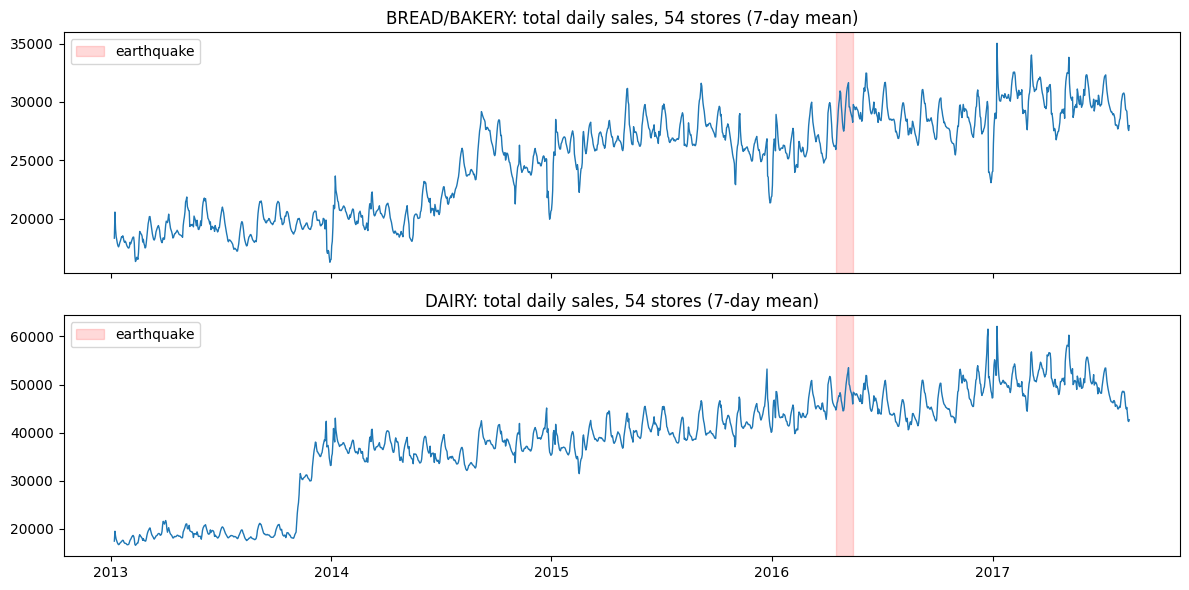

Ratios > 1 mean higher relative sales in that condition:


,family,weekend_vs_weekday,payday_vs_other,national_holiday_vs_other,promo_vs_no_promo,dow_Mon,dow_Tue,dow_Wed,dow_Thu,dow_Fri,dow_Sat,dow_Sun
0,BREAD/BAKERY,1.342,1.023,1.053,1.168,1.015,0.928,0.912,0.829,0.872,1.123,1.322
1,DAIRY,1.393,1.031,1.189,1.410,0.988,0.910,0.941,0.795,0.860,1.181,1.324


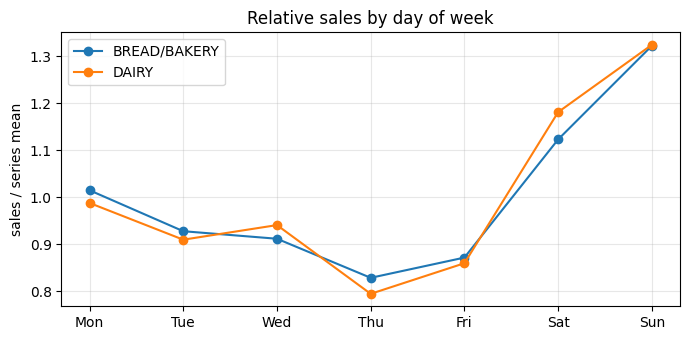

In [ ]:
fig, ax = plt.subplots(2, 1, figsize=(12, 6), sharex=True)
for i, f in enumerate(FAMILIES):
    tot = pd.Series(SALES[FAM_IDX == i].sum(0), index=dates)
    ax[i].plot(tot.rolling(7).mean(), lw=1); ax[i].set_title(f"{f}: total daily sales, 54 stores (7-day mean)")
    ax[i].axvspan(pd.Timestamp("2016-04-16"), pd.Timestamp("2016-05-15"), color="red", alpha=.15, label="earthquake")
    ax[i].legend()
plt.tight_layout(); plt.savefig(f"{OUT_DIR}/fig_eda_total_sales.png", dpi=130); plt.show()

eda = []
mask = OPEN > 0
for i, f in enumerate(FAMILIES):
    r = (FAM_IDX == i)[:, None] & mask
    rel = SALES / np.maximum(np.nanmean(np.where(mask, SALES, np.nan), axis=1, keepdims=True), 1e-9)
    by_dow = [rel[r & (DOW[None] == d)].mean() for d in range(7)]
    eda.append(dict(family=f,
        weekend_vs_weekday=np.mean(by_dow[5:]) / np.mean(by_dow[:5]),
        payday_vs_other=rel[r & (PAYDAY[None] == 1)].mean() / rel[r & (PAYDAY[None] == 0)].mean(),
        national_holiday_vs_other=rel[r & (HOL[..., 0] == 1)].mean() / rel[r & (HOL[..., 0] == 0)].mean(),
        promo_vs_no_promo=rel[r & (PROMO_RAW > 0)].mean() / rel[r & (PROMO_RAW == 0)].mean(),
        **{f"dow_{d}": v for d, v in zip(["Mon","Tue","Wed","Thu","Fri","Sat","Sun"], by_dow)}))
EDA = pd.DataFrame(eda).round(3)
EDA.to_csv(f"{OUT_DIR}/eda_summary.csv", index=False)
print("Ratios > 1 mean higher relative sales in that condition:")
display(EDA)

plt.figure(figsize=(7, 3.5))
for i, f in enumerate(FAMILIES):
    plt.plot(["Mon","Tue","Wed","Thu","Fri","Sat","Sun"], EDA.loc[i, [c for c in EDA if c.startswith("dow_")]].values, marker="o", label=f)
plt.title("Relative sales by day of week"); plt.ylabel("sales / series mean"); plt.legend(); plt.grid(alpha=.3)
plt.tight_layout(); plt.savefig(f"{OUT_DIR}/fig_eda_dow.png", dpi=130); plt.show()

## 5. Baselines: seasonal naive and ETS
Both are local models refitted at every origin with the history available up to that day.

In [ ]:
Z = 1.2816   # normal quantile for 10 % / 90 %

def seasonal_naive(o):
    P = np.zeros((S, H, 3), np.float32)
    hist, op = Y[:, o-364:o], OPEN[:, o-364:o] > 0
    d, ok = hist[:, 7:] - hist[:, :-7], op[:, 7:] & op[:, :-7]
    for s in range(S):
        dd = d[s][ok[s]]
        lo, hi = np.quantile(dd, [0.1, 0.9]) if len(dd) > 20 else (-0.3, 0.3)
        fc = Y[s, o-7:o][np.arange(H) % 7]          # same weekday of last week
        P[s, :, 0], P[s, :, 1], P[s, :, 2] = fc + lo, fc, fc + hi
    return P

t0 = time.time()
PREDS["Seasonal naive"] = {o: seasonal_naive(o) for o in VAL_O + [TEST_O]}
print(f"seasonal naive: {time.time()-t0:.1f}s")

seasonal naive: 0.5s


In [ ]:
from statsmodels.tsa.holtwinters import ExponentialSmoothing

def ets(o):
    P = np.zeros((S, H, 3), np.float32)
    naive = seasonal_naive(o)
    for s in range(S):
        y, m = Y[s, o-364:o].astype(float).copy(), OPEN[s, o-364:o] > 0
        for t in range(7, len(y)):                  # closed days: copy same weekday of last week
            if not m[t]: y[t] = y[t-7]
        try:
            fit = ExponentialSmoothing(y, trend=None, seasonal="add", seasonal_periods=7,
                                       initialization_method="estimated").fit()
            fc, sd = fit.forecast(H), np.std(fit.resid[28:])
            P[s, :, 0], P[s, :, 1], P[s, :, 2] = fc - Z*sd, fc, fc + Z*sd
        except Exception:
            P[s] = naive[s]
    return P

t0 = time.time()
PREDS["ETS"] = {o: ets(o) for o in VAL_O + [TEST_O]}
print(f"ETS: {time.time()-t0:.1f}s")

ETS: 29.4s


## 6. Quantile LightGBM (global model, direct multi-horizon)
One row per (series, origin, horizon day). Features only use history **before** the origin, so the same information is available as for the network. Validation: trained with targets up to May 27, 2017 and early-stopped on the 4 folds; test: refitted with targets up to Jul 30, 2017 with the best number of trees.

In [ ]:
CAT_COLS = ["store", "type", "cluster", "family"]

def lgb_features(o):
    s_idx, hh = np.repeat(np.arange(S), H), np.tile(np.arange(H), S)
    t = o + hh
    rep = lambda v: np.repeat(v, H)
    X = {"h": hh, "store": STORE_IDX[s_idx], "type": TYPE_IDX[s_idx], "cluster": CLUSTER_IDX[s_idx],
         "family": FAM_IDX[s_idx], "dow": DOW[t], "dom": DOM[t], "month": MONTH[t], "payday": PAYDAY[t],
         "hol_nat": HOL[s_idx, t, 0], "hol_reg": HOL[s_idx, t, 1], "hol_loc": HOL[s_idx, t, 2],
         "promo": PROMO[s_idx, t], "closed": CLOSED[s_idx, t], "quake": QUAKE[t],
         "last1": rep(Y[:, o-1]), "std28": rep(Y[:, o-28:o].std(1)),
         "promo_hist28": rep(PROMO[:, o-28:o].mean(1)), "trans7": rep(TRANS[:, o-7:o].mean(1)),
         "oil_last": np.full(S*H, OIL[o-1])}
    for k in (7, 14, 28, 56):
        X[f"mean{k}"] = rep(Y[:, o-k:o].mean(1))
    k0 = hh // 7 + 1                                   # weeks back so that the day is before the origin
    sw = np.stack([Y[s_idx, t - 7*(k0 + j)] for j in range(4)], 1)
    X["sdow_last"], X["sdow_mean4"] = sw[:, 0], sw.mean(1)
    X = pd.DataFrame(X)
    keep = (OPEN[s_idx, t] > 0) & (o - ENC_LEN >= FIRST[s_idx])
    return X, Y[s_idx, t], keep

LGB_START = date_idx[pd.Timestamp("2015-01-01")]   # LightGBM uses origins from 2015 on (speed)

def lgb_dataset(last_target, step=4):
    Xs, ys = [], []
    for o in range(max(ENC_LEN, LGB_START), last_target - H + 2, step):
        X, y, k = lgb_features(o); Xs.append(X[k]); ys.append(y[k])
    return pd.concat(Xs, ignore_index=True), np.concatenate(ys)

def lgb_predict(models, o):
    X, _, _ = lgb_features(o)
    P = np.stack([m.predict(X) for m in models], -1).reshape(S, H, 3)
    return np.sort(P, -1)

LightGBM train rows: 353626 | validation rows: 6848
best iterations: [365, 959, 823]
LightGBM: 4.2 min


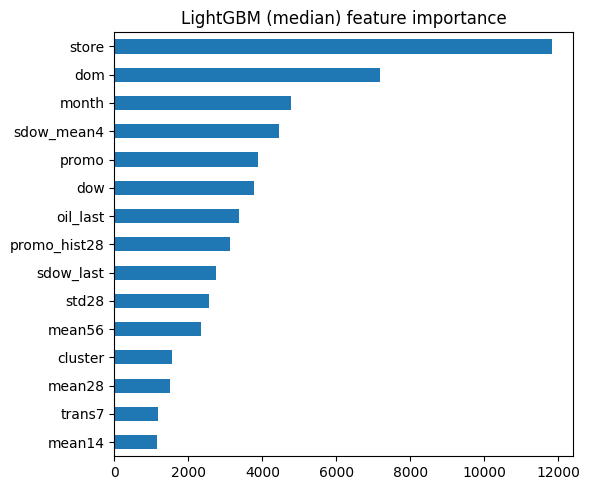

In [ ]:
import lightgbm as lgb
LGB_PARAMS = dict(objective="quantile", n_estimators=1500, learning_rate=0.06, num_leaves=63,
                  min_child_samples=100, max_bin=127, subsample=0.8, subsample_freq=1, colsample_bytree=0.8,
                  random_state=SEED, verbose=-1)
t0 = time.time()
Xtr, ytr = lgb_dataset(VAL_O[0] - 1)
_va = [lgb_features(o) for o in VAL_O]
Xva = pd.concat([X[k] for X, _, k in _va], ignore_index=True)
yva = np.concatenate([y[k] for _, y, k in _va])
print("LightGBM train rows:", len(Xtr), "| validation rows:", len(Xva))
lgb_val, best_iters = [], []
for tau in QUANTILES:
    m = lgb.LGBMRegressor(alpha=tau, **LGB_PARAMS)
    m.fit(Xtr, ytr, eval_set=[(Xva, yva)], categorical_feature=CAT_COLS,
          callbacks=[lgb.early_stopping(100, verbose=False)])
    lgb_val.append(m); best_iters.append(max(m.best_iteration_ or LGB_PARAMS["n_estimators"], 50))
print("best iterations:", best_iters)
PREDS["LightGBM"] = {o: lgb_predict(lgb_val, o) for o in VAL_O}

Xtr2, ytr2 = lgb_dataset(TEST_O - 1)
lgb_test = []
for tau, it in zip(QUANTILES, best_iters):
    m = lgb.LGBMRegressor(alpha=tau, **{**LGB_PARAMS, "n_estimators": it})
    m.fit(Xtr2, ytr2, categorical_feature=CAT_COLS); lgb_test.append(m)
PREDS["LightGBM"][TEST_O] = lgb_predict(lgb_test, TEST_O)
print(f"LightGBM: {(time.time()-t0)/60:.1f} min")

imp = pd.Series(lgb_test[1].feature_importances_, index=Xtr2.columns).sort_values()
imp.tail(15).plot.barh(figsize=(6, 5), title="LightGBM (median) feature importance")
plt.tight_layout(); plt.savefig(f"{OUT_DIR}/fig_lgb_importance.png", dpi=130); plt.show()

## 7. LSTM encoder–decoder with embeddings and non-crossing quantile head
* **Encoder** (2-layer LSTM): 56 days of scaled log-sales + transactions + oil + known covariates + embeddings.
* **Decoder** (2-layer LSTM): known covariates of the 16 future days + embeddings, initialized with the encoder state.
* **Head**: median and two positive offsets (softplus) ⇒ q0.1 ≤ q0.5 ≤ q0.9 always.
* **Scaling**: each window is divided by the mean log-sales of its encoder (per store–family series).
* **Loss**: pinball loss averaged over the 3 quantiles, ignoring closed days.
* Stage 1: train with targets up to May 27, 2017, early stopping on the 4 validation folds. Stage 2: retrain from scratch with targets up to Jul 30, 2017 for the best number of epochs and forecast the test window.

device: cuda
--- LSTM enc-dec: stage 1 (validation) ---
epoch 01  train 0.0418  val 0.0109
epoch 02  train 0.0203  val 0.0107
epoch 03  train 0.0189  val 0.0096
epoch 04  train 0.0178  val 0.0093
epoch 05  train 0.0164  val 0.0086
epoch 06  train 0.0149  val 0.0074
epoch 07  train 0.0132  val 0.0069
epoch 08  train 0.0118  val 0.0064
epoch 09  train 0.0107  val 0.0061
epoch 10  train 0.0094  val 0.0060
epoch 11  train 0.0084  val 0.0058
epoch 12  train 0.0078  val 0.0057
epoch 13  train 0.0076  val 0.0058
epoch 14  train 0.0072  val 0.0056
epoch 15  train 0.0073  val 0.0055
epoch 16  train 0.0069  val 0.0055
epoch 17  train 0.0069  val 0.0056
epoch 18  train 0.0068  val 0.0056
epoch 19  train 0.0067  val 0.0055
epoch 20  train 0.0065  val 0.0055
epoch 21  train 0.0064  val 0.0055
epoch 22  train 0.0063  val 0.0054
epoch 23  train 0.0065  val 0.0055
epoch 24  train 0.0062  val 0.0055
epoch 25  train 0.0063  val 0.0055
epoch 26  train 0.0061  val 0.0054
epoch 27  train 0.0061  val 0.0054

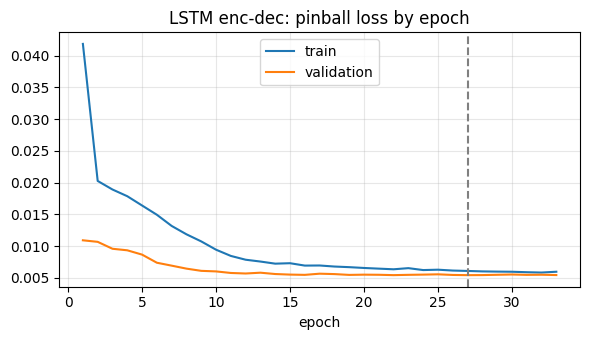

LSTM enc-dec: 2.1 min, best epoch 27


In [ ]:
import torch, torch.nn as nn, torch.nn.functional as F
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
print("device:", DEVICE)
Y_T, OPEN_T = torch.tensor(Y, device=DEVICE), torch.tensor(OPEN, device=DEVICE)
KNOWN_T, PAST_T = torch.tensor(KNOWN, device=DEVICE), torch.tensor(PAST, device=DEVICE)
CATS_T = torch.tensor(np.stack([STORE_IDX, TYPE_IDX, CLUSTER_IDX, FAM_IDX], 1), dtype=torch.long, device=DEVICE)
OFFS = torch.arange(-ENC_LEN, H, device=DEVICE)
QT = torch.tensor(QUANTILES, device=DEVICE)
N_KNOWN, N_PAST = KNOWN.shape[-1], PAST.shape[-1]

def make_batch(s, o):
    tidx = o[:, None] + OFFS[None]
    sidx = s[:, None].expand_as(tidx)
    y, op, kn, pa = Y_T[sidx, tidx], OPEN_T[sidx, tidx], KNOWN_T[sidx, tidx], PAST_T[sidx, tidx]
    ye, oe = y[:, :ENC_LEN], op[:, :ENC_LEN]
    scale = ((ye * oe).sum(1) / oe.sum(1).clamp(min=1)).clamp(min=1.0)
    ys = y / scale[:, None]
    enc = torch.cat([ys[:, :ENC_LEN, None], pa[:, :ENC_LEN], kn[:, :ENC_LEN]], -1)
    return enc, kn[:, ENC_LEN:], CATS_T[s], ys[:, ENC_LEN:], op[:, ENC_LEN:], scale

class Seq2SeqQuantile(nn.Module):
    def __init__(self, cell="lstm", hidden=64, layers=2, dropout=0.2, emb=(8, 3, 4, 2)):
        super().__init__()
        self.embs = nn.ModuleList([nn.Embedding(c, e) for c, e in zip(CARD, emb)])
        E, RNN = sum(emb), (nn.LSTM if cell == "lstm" else nn.GRU)
        self.encoder = RNN(1 + N_PAST + N_KNOWN + E, hidden, layers, batch_first=True, dropout=dropout)
        self.decoder = RNN(N_KNOWN + E, hidden, layers, batch_first=True, dropout=dropout)
        self.drop, self.head = nn.Dropout(dropout), nn.Linear(hidden, 3)
    def forward(self, enc, dec, cats):
        e = torch.cat([m(cats[:, i]) for i, m in enumerate(self.embs)], -1)
        enc = torch.cat([enc, e[:, None].expand(-1, enc.size(1), -1)], -1)
        dec = torch.cat([dec, e[:, None].expand(-1, dec.size(1), -1)], -1)
        _, state = self.encoder(enc)
        out, _ = self.decoder(dec, state)
        z = self.head(self.drop(out))
        med = z[..., 0]
        return torch.stack([med - F.softplus(z[..., 1]), med, med + F.softplus(z[..., 2])], -1)

def qloss(pred, y, m):
    d = y[..., None] - pred
    return (torch.maximum(QT * d, (QT - 1) * d).mean(-1) * m).sum() / m.sum().clamp(min=1)

def train_pairs(last_target):
    ss, oo = [], []
    for s in range(S):
        start, end = FIRST[s] + ENC_LEN, last_target - H + 1
        if end >= start:
            o = np.arange(start, end + 1); ss.append(np.full(len(o), s)); oo.append(o)
    return (torch.tensor(np.concatenate(ss), device=DEVICE), torch.tensor(np.concatenate(oo), device=DEVICE))

def all_series(o):
    return torch.arange(S, device=DEVICE), torch.full((S,), o, device=DEVICE, dtype=torch.long)

def train_nn(cell, last_target, val_origins=None, epochs=40, steps=300, bs=256, lr=1e-3, patience=6, **kw):
    torch.manual_seed(SEED); np.random.seed(SEED)
    model = Seq2SeqQuantile(cell, **kw).to(DEVICE)
    opt = torch.optim.Adam(model.parameters(), lr=lr)
    ps, po = train_pairs(last_target)
    best, best_state, best_ep, wait, hist = 1e9, None, epochs, 0, []
    for ep in range(1, epochs + 1):
        model.train(); tl = 0.0
        for _ in range(steps):
            i = torch.randint(0, len(ps), (bs,), device=DEVICE)
            enc, dec, cats, yt, mt, _ = make_batch(ps[i], po[i])
            loss = qloss(model(enc, dec, cats), yt, mt)
            opt.zero_grad(); loss.backward(); nn.utils.clip_grad_norm_(model.parameters(), 1.0); opt.step()
            tl += loss.item()
        row = {"epoch": ep, "train": tl / steps}
        if val_origins:
            model.eval()
            with torch.no_grad():
                vl = []
                for o in val_origins:
                    enc, dec, cats, yt, mt, _ = make_batch(*all_series(o))
                    vl.append(qloss(model(enc, dec, cats), yt, mt).item())
            row["val"] = float(np.mean(vl))
            if row["val"] < best:
                best, best_state, best_ep, wait = row["val"], copy.deepcopy(model.state_dict()), ep, 0
            else:
                wait += 1
        hist.append(row)
        print(f"epoch {ep:02d}  train {row['train']:.4f}" + (f"  val {row['val']:.4f}" if val_origins else ""))
        if val_origins and wait >= patience:
            print(f"early stopping, best epoch {best_ep}"); break
    if best_state is not None: model.load_state_dict(best_state)
    return model, best_ep, pd.DataFrame(hist)

@torch.no_grad()
def nn_predict(model, o):
    model.eval()
    enc, dec, cats, _, _, scale = make_batch(*all_series(o))
    return (model(enc, dec, cats) * scale[:, None, None]).clamp(min=0).cpu().numpy()

def run_nn(name, cell, **kw):
    t0 = time.time()
    print(f"--- {name}: stage 1 (validation) ---")
    mv, best_ep, hist = train_nn(cell, VAL_O[0] - 1, val_origins=VAL_O, **kw)
    PREDS[name] = {o: nn_predict(mv, o) for o in VAL_O}
    print(f"--- {name}: stage 2 (retrain {best_ep} epochs, forecast test) ---")
    mt, _, _ = train_nn(cell, TEST_O - 1, epochs=best_ep, **kw)
    PREDS[name][TEST_O] = nn_predict(mt, TEST_O)
    hist.to_csv(f"{OUT_DIR}/training_curve_{cell}.csv", index=False)
    plt.figure(figsize=(6, 3.5)); plt.plot(hist.epoch, hist.train, label="train")
    plt.plot(hist.epoch, hist.val, label="validation"); plt.axvline(best_ep, ls="--", c="gray")
    plt.title(f"{name}: pinball loss by epoch"); plt.xlabel("epoch"); plt.legend(); plt.grid(alpha=.3)
    plt.tight_layout(); plt.savefig(f"{OUT_DIR}/fig_training_{cell}.png", dpi=130); plt.show()
    print(f"{name}: {(time.time()-t0)/60:.1f} min, best epoch {best_ep}")
    return mt, best_ep

lstm_model, lstm_epochs = run_nn("LSTM enc-dec", "lstm")

## 8. GRU variant (same architecture, GRU cells)

--- GRU enc-dec: stage 1 (validation) ---
epoch 01  train 0.0320  val 0.0103
epoch 02  train 0.0188  val 0.0096
epoch 03  train 0.0172  val 0.0092
epoch 04  train 0.0159  val 0.0082
epoch 05  train 0.0144  val 0.0076
epoch 06  train 0.0131  val 0.0074
epoch 07  train 0.0115  val 0.0068
epoch 08  train 0.0105  val 0.0064
epoch 09  train 0.0095  val 0.0061
epoch 10  train 0.0085  val 0.0060
epoch 11  train 0.0081  val 0.0058
epoch 12  train 0.0078  val 0.0056
epoch 13  train 0.0076  val 0.0056
epoch 14  train 0.0073  val 0.0055
epoch 15  train 0.0072  val 0.0055
epoch 16  train 0.0071  val 0.0056
epoch 17  train 0.0070  val 0.0055
epoch 18  train 0.0069  val 0.0057
epoch 19  train 0.0068  val 0.0054
epoch 20  train 0.0067  val 0.0055
epoch 21  train 0.0067  val 0.0054
epoch 22  train 0.0066  val 0.0054
epoch 23  train 0.0065  val 0.0056
epoch 24  train 0.0065  val 0.0056
epoch 25  train 0.0064  val 0.0057
epoch 26  train 0.0064  val 0.0057
epoch 27  train 0.0063  val 0.0056
epoch 28  tra

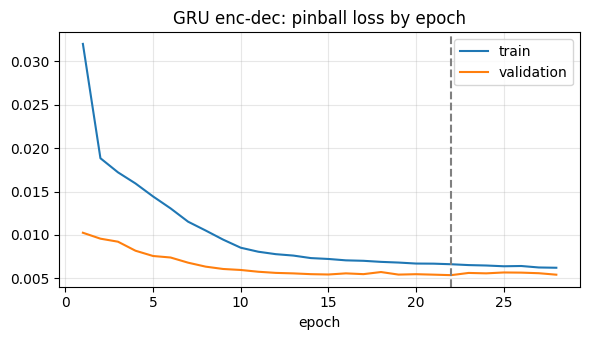

GRU enc-dec: 1.6 min, best epoch 22


In [ ]:
gru_model, gru_epochs = run_nn("GRU enc-dec", "gru")

## 9. Results: validation (mean of 4 folds) and holdout test, by family

In [ ]:
RESULTS.clear()
for name, p in PREDS.items():
    if not all(o in p for o in VAL_O + [TEST_O]): continue
    evaluate(name, "validation", {o: p[o] for o in VAL_O})
    evaluate(name, "test", {TEST_O: p[TEST_O]})
res = pd.DataFrame(RESULTS)
res.to_csv(f"{OUT_DIR}/results_phase3.csv", index=False)
cols = ["model", "family", "RMSLE", "WAPE_pct", "MAE", "Pinball_log", "Coverage_10_90_pct"]
for split in ["validation", "test"]:
    print(f"\n===== {split.upper()} =====")
    display(res[res.split == split][cols].sort_values(["family", "RMSLE"]).round(4))

best = res[res.split == "test"].sort_values("RMSLE").groupby("family").head(1)[["family", "model", "RMSLE"]]
print("\nBest model on the test set by RMSLE:"); display(best)


===== VALIDATION =====


,model,family,RMSLE,WAPE_pct,MAE,Pinball_log,Coverage_10_90_pct
8,LightGBM,BREAD/BAKERY,0.1387,9.2210,51.3952,0.0339,73.1192
16,GRU enc-dec,BREAD/BAKERY,0.1433,9.3368,52.0408,0.0344,78.0961
12,LSTM enc-dec,BREAD/BAKERY,0.1454,9.4463,52.6509,0.0350,76.0417
4,ETS,BREAD/BAKERY,0.1572,10.6763,59.5065,0.0384,85.2141
0,Seasonal naive,BREAD/BAKERY,0.1918,12.4804,69.5618,0.0465,85.6192
9,LightGBM,DAIRY,0.1200,8.0882,74.3254,0.0292,76.0417
13,LSTM enc-dec,DAIRY,0.1274,8.5287,78.3731,0.0305,80.0347
17,GRU enc-dec,DAIRY,0.1284,8.5921,78.9553,0.0308,78.8484
5,ETS,DAIRY,0.1430,10.0727,92.5611,0.0355,87.4421
1,Seasonal naive,DAIRY,0.1692,11.7086,107.5943,0.0420,89.6701



===== TEST =====


,model,family,RMSLE,WAPE_pct,MAE,Pinball_log,Coverage_10_90_pct
10,LightGBM,BREAD/BAKERY,0.1650,10.2803,55.5415,0.0385,71.0648
14,LSTM enc-dec,BREAD/BAKERY,0.1659,10.5272,56.8757,0.0388,74.3056
18,GRU enc-dec,BREAD/BAKERY,0.1819,10.8748,58.7538,0.0428,71.6435
6,ETS,BREAD/BAKERY,0.1867,12.5455,67.7798,0.0451,77.3148
2,Seasonal naive,BREAD/BAKERY,0.2159,14.1538,76.4688,0.0509,83.2176
15,LSTM enc-dec,DAIRY,0.1245,7.9812,66.6058,0.0298,81.4815
11,LightGBM,DAIRY,0.1322,9.2440,77.1442,0.0317,73.4954
19,GRU enc-dec,DAIRY,0.1333,8.9059,74.3222,0.0318,76.9676
7,ETS,DAIRY,0.1743,12.1892,101.7229,0.0429,77.0833
3,Seasonal naive,DAIRY,0.1994,13.8794,115.8275,0.0480,82.2917



Best model on the test set by RMSLE:


,family,model,RMSLE
15,DAIRY,LSTM enc-dec,0.124491
10,BREAD/BAKERY,LightGBM,0.165035


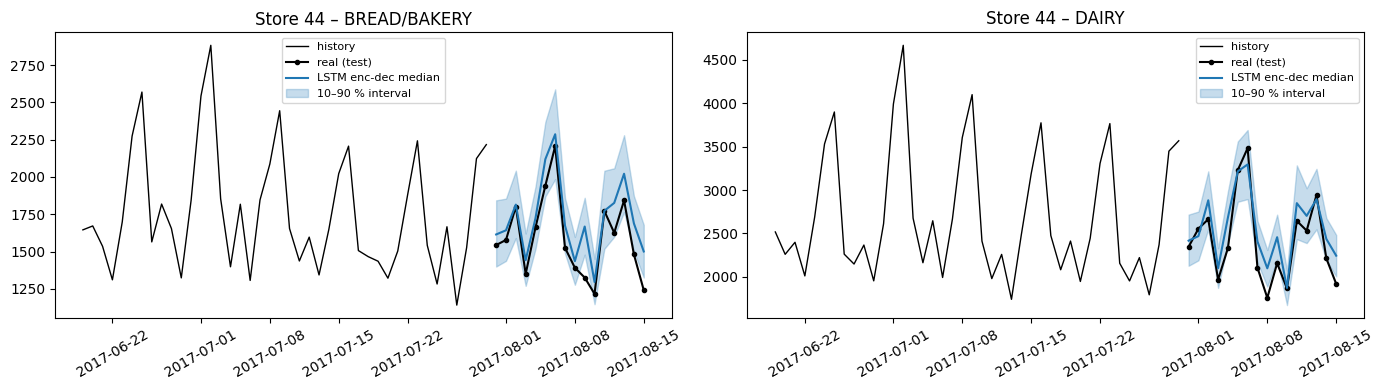

In [ ]:
# Forecast example: the store with the highest bread sales
s_store = int(np.argmax(SALES[FAM_IDX == 0, -365:].sum(1)))
fig, ax = plt.subplots(1, 2, figsize=(14, 4))
for fam in range(2):
    s = fam * len(store_ids) + s_store
    d_hist = dates[TEST_O-42:TEST_O]; d_fut = dates[TEST_O:TEST_O+H]
    ax[fam].plot(d_hist, SALES[s, TEST_O-42:TEST_O], c="k", lw=1, label="history")
    ax[fam].plot(d_fut, SALES[s, TEST_O:TEST_O+H], c="k", marker="o", ms=3, label="real (test)")
    name = "LSTM enc-dec" if "LSTM enc-dec" in PREDS else list(PREDS)[-1]
    q = np.expm1(PREDS[name][TEST_O][s])
    ax[fam].plot(d_fut, q[:, 1], c="C0", label=f"{name} median")
    ax[fam].fill_between(d_fut, q[:, 0], q[:, 2], color="C0", alpha=.25, label="10–90 % interval")
    ax[fam].set_title(f"Store {store_ids[s_store]} – {FAMILIES[fam]}"); ax[fam].legend(fontsize=8); ax[fam].tick_params(axis="x", rotation=30)
plt.tight_layout(); plt.savefig(f"{OUT_DIR}/fig_forecast_example.png", dpi=130); plt.show()

## 10. Decision layer: newsvendor order, anomaly alerts and explanations
**Newsvendor**: recommended quantity = quantile τ* = cᵤ/(cᵤ+cₒ), interpolated between the 3 estimated quantiles. Cost of the recommendation vs. ordering the median, on the test window, for cost ratios cᵤ:cₒ = 1:1, 2:1 and 4:1.

In [ ]:
def quantile_at(q, tau):            # q [...,3] in log space, linear interpolation
    tau = float(np.clip(tau, 0.1, 0.9))
    if tau <= 0.5: return q[..., 0] + (tau - 0.1) / 0.4 * (q[..., 1] - q[..., 0])
    return q[..., 1] + (tau - 0.5) / 0.4 * (q[..., 2] - q[..., 1])

nv = []
y_test, m_test = SALES[:, TEST_O:TEST_O+H], OPEN[:, TEST_O:TEST_O+H] > 0
for name in [n for n in ["LSTM enc-dec", "GRU enc-dec", "LightGBM"] if n in PREDS]:
    q = np.sort(PREDS[name][TEST_O], -1)
    for ratio in [1, 2, 4]:
        tau = ratio / (ratio + 1)
        for fam in range(2):
            r = (FAM_IDX == fam)[:, None] & m_test
            cost = lambda Q: (ratio * np.maximum(y_test - Q, 0) + np.maximum(Q - y_test, 0))[r].sum()
            c_med, c_nv = cost(np.expm1(q[..., 1])), cost(np.expm1(quantile_at(q, tau)))
            nv.append(dict(model=name, family=FAMILIES[fam], cost_ratio=f"{ratio}:1", tau_star=round(tau, 3),
                           cost_median=round(c_med), cost_newsvendor=round(c_nv),
                           saving_pct=round(100 * (c_med - c_nv) / c_med, 2)))
NV = pd.DataFrame(nv); NV.to_csv(f"{OUT_DIR}/newsvendor_phase3.csv", index=False); display(NV)

,model,family,cost_ratio,tau_star,cost_median,cost_newsvendor,saving_pct
0,LSTM enc-dec,BREAD/BAKERY,1:1,0.500,49141,49141,0.000000
1,LSTM enc-dec,DAIRY,1:1,0.500,57547,57547,0.000000
2,LSTM enc-dec,BREAD/BAKERY,2:1,0.667,73762,72005,2.380000
3,LSTM enc-dec,DAIRY,2:1,0.667,75397,87728,-16.350000
4,LSTM enc-dec,BREAD/BAKERY,4:1,0.800,123005,100280,18.469999
5,LSTM enc-dec,DAIRY,4:1,0.800,111097,121549,-9.410000
6,GRU enc-dec,BREAD/BAKERY,1:1,0.500,50763,50763,0.000000
7,GRU enc-dec,DAIRY,1:1,0.500,64214,64214,0.000000
8,GRU enc-dec,BREAD/BAKERY,2:1,0.667,83391,75327,9.670000
9,GRU enc-dec,DAIRY,2:1,0.667,86587,95002,-9.720000


**Anomaly alerts** (test window): *warning* = real sales outside the 10–90 % interval on 2 consecutive days; *critical* = outside by more than 50 % of the interval width on one day.

In [ ]:
al = []
for name in [n for n in ["LSTM enc-dec", "LightGBM"] if n in PREDS]:
    q = np.sort(PREDS[name][TEST_O], -1); y = Y[:, TEST_O:TEST_O+H]
    out = ((y < q[..., 0]) | (y > q[..., 2])) & m_test
    width = q[..., 2] - q[..., 0]
    dist = np.maximum(q[..., 0] - y, y - q[..., 2])
    warn = out[:, 1:] & out[:, :-1]
    crit = (dist > 0.5 * width) & m_test
    for fam in range(2):
        r = FAM_IDX == fam
        al.append(dict(model=name, family=FAMILIES[fam],
                       days_outside_interval_pct=round(100 * out[r].sum() / m_test[r].sum(), 2),
                       warning_alerts=int(warn[r].sum()), critical_alerts=int(crit[r].sum()),
                       series_with_any_alert=int((warn[r].any(1) | crit[r].any(1)).sum())))
AL = pd.DataFrame(al); AL.to_csv(f"{OUT_DIR}/anomaly_alerts_phase3.csv", index=False); display(AL)

,model,family,days_outside_interval_pct,warning_alerts,critical_alerts,series_with_any_alert
0,LSTM enc-dec,BREAD/BAKERY,25.69,75,34,40
1,LSTM enc-dec,DAIRY,18.52,44,13,28
2,LightGBM,BREAD/BAKERY,28.94,86,39,41
3,LightGBM,DAIRY,26.50,73,36,41


**Integrated gradients** for the LSTM median forecast (test window). Baseline: average week (day-of-week channels = 1/7), no promotion, no holiday, no payday, history replaced by its mean. Attributions are grouped into the 5 factors shown in the app.

Share of attribution (%) by factor:


,Recent history,Day of week,Payday,Holiday,Promotion
family,,,,,
BREAD/BAKERY,0.5,18.100000,34.700001,7.8,39.0
DAIRY,0.4,20.200001,45.900002,10.0,23.6


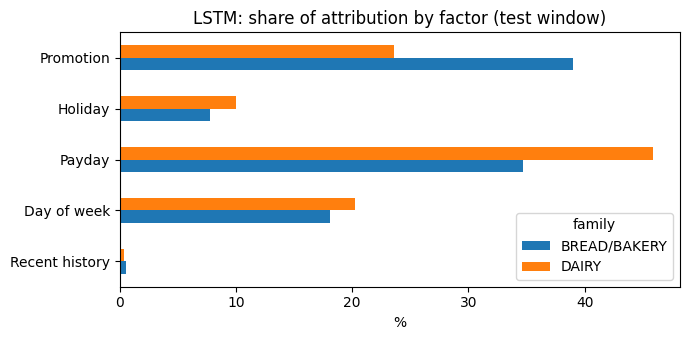

In [ ]:
GROUPS = {"Recent history": ("enc", [0]), "Day of week": ("known", list(range(7))),
          "Payday": ("known", [11]), "Holiday": ("known", [12, 13, 14]), "Promotion": ("known", [15])}

def integrated_gradients(model, o, steps=32):
    model.eval()
    enc, dec, cats, _, _, _ = make_batch(*all_series(o))
    eb, db = enc.clone(), dec.clone()
    eb[:, :, 0] = enc[:, :, 0].mean(1, keepdim=True)
    for X, off in [(eb, 1 + N_PAST), (db, 0)]:
        X[:, :, off:off+7] = 1/7; X[:, :, off+11:off+16] = 0
    ge_sum, gd_sum = torch.zeros_like(enc), torch.zeros_like(dec)
    with torch.backends.cudnn.flags(enabled=False):          # RNN backward in eval mode
        for a in np.linspace(1/steps, 1, steps):
            xe = (eb + float(a) * (enc - eb)).requires_grad_(True)
            xd = (db + float(a) * (dec - db)).requires_grad_(True)
            ge, gd = torch.autograd.grad(model(xe, xd, cats)[..., 1].sum(), [xe, xd])
            ge_sum += ge; gd_sum += gd
    ae, ad = ((enc - eb) * ge_sum / steps).cpu().numpy(), ((dec - db) * gd_sum / steps).cpu().numpy()
    out = {}
    for g, (kind, ch) in GROUPS.items():
        if kind == "enc": out[g] = ae[:, :, ch].sum((1, 2))
        else: out[g] = ae[:, :, [1 + N_PAST + c for c in ch]].sum((1, 2)) + ad[:, :, ch].sum((1, 2))
    return pd.DataFrame(out)

IG = integrated_gradients(lstm_model, TEST_O)
IG["family"] = [FAMILIES[f] for f in FAM_IDX]
share = IG.groupby("family").agg(lambda v: np.abs(v).mean())
share = (100 * share.div(share.sum(1), axis=0)).round(1)
share.to_csv(f"{OUT_DIR}/integrated_gradients_share.csv"); print("Share of attribution (%) by factor:"); display(share)
share.T.plot.barh(figsize=(7, 3.5), title="LSTM: share of attribution by factor (test window)")
plt.xlabel("%"); plt.tight_layout(); plt.savefig(f"{OUT_DIR}/fig_integrated_gradients.png", dpi=130); plt.show()

## 11. (Optional) Temporal Fusion Transformer
Set `RUN_TFT = True` in step 0. Uses PyTorch Forecasting; trained with targets up to Jul 14, 2017 and early-stopped on fold 4, then forecasts the test window. If installation or training fails in Colab, the rest of the results are still valid and the TFT is reported as pending.

In [ ]:
if RUN_TFT:
    !pip -q install pytorch-forecasting lightning

In [ ]:
if RUN_TFT:
    try:
        import lightning.pytorch as pl
        from lightning.pytorch.callbacks import EarlyStopping
        from pytorch_forecasting import TimeSeriesDataSet, TemporalFusionTransformer
        from pytorch_forecasting.data import GroupNormalizer
        from pytorch_forecasting.metrics import QuantileLoss
        pl.seed_everything(SEED)
        rows = []
        for s in range(S):
            t = np.arange(max(FIRST[s], 0), T)
            rows.append(pd.DataFrame({"series": str(s), "time_idx": t, "y": Y[s, t],
                "store": str(STORE_IDX[s]), "family": FAMILIES[FAM_IDX[s]], "type": str(TYPE_IDX[s]),
                "cluster": str(CLUSTER_IDX[s]), "dow": DOW[t].astype(str), "payday": PAYDAY[t],
                "hol_nat": HOL[s, t, 0], "hol_reg": HOL[s, t, 1], "hol_loc": HOL[s, t, 2],
                "promo": PROMO[s, t], "closed": CLOSED[s, t], "quake": QUAKE[t],
                "dom_sin": KNOWN[s, t, 7], "dom_cos": KNOWN[s, t, 8], "m_sin": KNOWN[s, t, 9], "m_cos": KNOWN[s, t, 10],
                "trans": TRANS[s, t], "oil": OIL[t]}))
        df = pd.concat(rows, ignore_index=True)
        params = dict(time_idx="time_idx", target="y", group_ids=["series"],
            max_encoder_length=ENC_LEN, max_prediction_length=H,
            static_categoricals=["store", "family", "type", "cluster"],
            time_varying_known_categoricals=["dow"],
            time_varying_known_reals=["time_idx", "payday", "hol_nat", "hol_reg", "hol_loc", "promo", "closed",
                                      "quake", "dom_sin", "dom_cos", "m_sin", "m_cos"],
            time_varying_unknown_reals=["y", "trans", "oil"],
            target_normalizer=GroupNormalizer(groups=["series"]), add_relative_time_idx=True, add_encoder_length=True)
        training = TimeSeriesDataSet(df[df.time_idx < VAL_O[3]], **params)
        val_ds = TimeSeriesDataSet.from_dataset(training, df[df.time_idx < TEST_O], predict=True, stop_randomization=True)
        test_ds = TimeSeriesDataSet.from_dataset(training, df, predict=True, stop_randomization=True)
        tdl = training.to_dataloader(train=True, batch_size=256, num_workers=2)
        vdl = val_ds.to_dataloader(train=False, batch_size=256, num_workers=2)
        xdl = test_ds.to_dataloader(train=False, batch_size=256, num_workers=2)
        tft = TemporalFusionTransformer.from_dataset(training, learning_rate=1e-3, hidden_size=32,
            attention_head_size=2, dropout=0.2, hidden_continuous_size=16,
            loss=QuantileLoss(QUANTILES), log_interval=0)
        trainer = pl.Trainer(max_epochs=15, accelerator="auto", gradient_clip_val=0.1, limit_train_batches=200,
                             callbacks=[EarlyStopping(monitor="val_loss", patience=3)], enable_model_summary=False)
        t0 = time.time(); trainer.fit(tft, train_dataloaders=tdl, val_dataloaders=vdl)
        def tft_pred(dl):
            out = tft.predict(dl, mode="quantiles", return_index=True)
            q = out.output if hasattr(out, "output") else out[0]
            idx = out.index if hasattr(out, "index") else out[-1]
            q = q.cpu().numpy() if hasattr(q, "cpu") else np.asarray(q)
            P = np.zeros((S, H, 3), np.float32)
            for k, sid in enumerate(idx["series"].astype(int).values): P[sid] = q[k]
            return np.sort(P, -1)
        PREDS["TFT"] = {VAL_O[3]: tft_pred(vdl), TEST_O: tft_pred(xdl)}
        print(f"TFT: {(time.time()-t0)/60:.1f} min")
        evaluate("TFT", "validation (fold 4 only)", {VAL_O[3]: PREDS["TFT"][VAL_O[3]]})
        display(evaluate("TFT", "test", {TEST_O: PREDS["TFT"][TEST_O]}).round(4))
        try:
            raw = tft.predict(vdl, mode="raw", return_x=True)
            interp = tft.interpret_output(raw.output, reduction="sum")
            vi = pd.Series(interp["encoder_variables"].cpu().numpy(), index=tft.encoder_variables)
            vi = (100 * vi / vi.sum()).sort_values(ascending=False).round(1)
            vi.to_csv(f"{OUT_DIR}/tft_encoder_variable_importance.csv"); display(vi.head(10))
        except Exception as e:
            print("TFT variable importance not available in this version:", e)
        pd.DataFrame(RESULTS).to_csv(f"{OUT_DIR}/results_phase3.csv", index=False)
    except Exception as e:
        print("TFT could not run, report it as pending:", repr(e))

## 12. Download everything

In [ ]:
pd.DataFrame(RESULTS).to_csv(f"{OUT_DIR}/results_phase3.csv", index=False)
!cd /content && zip -q -r results_phase3.zip results
from google.colab import files
files.download("/content/results_phase3.zip")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>